In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


In [ ]:
X, y = make_classification(
    n_samples=1000,
    n_features=2,
    n_classes=2,
    n_redundant=0,
    n_informative=2,
    random_state=42
)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)



In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
def create_model(learning_rate):

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(2,)),
        tf.keras.layers.Dense(16, activation='relu'),
        tf.keras.layers.Dense(8, activation='relu'),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=learning_rate
    )

    model.compile(
        optimizer=optimizer,
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

In [ ]:
learning_rates = [0.001, 0.01, 0.1]

results_lr = {}

for lr in learning_rates:

    print("\nLearning Rate:", lr)

    model = create_model(lr)

    history = model.fit(
        X_train,
        y_train,
        epochs=50,
        batch_size=32,
        validation_split=0.2,
        verbose=0
    )

    test_loss, test_accuracy = model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    print("Test Loss:", test_loss)
    print("Test Accuracy:", test_accuracy)

    results_lr[lr] = history


Learning Rate: 0.001
Test Loss: 0.24121126532554626
Test Accuracy: 0.8849999904632568

Learning Rate: 0.01
Test Loss: 0.16317327320575714
Test Accuracy: 0.9300000071525574

Learning Rate: 0.1
Test Loss: 0.175038143992424
Test Accuracy: 0.9449999928474426


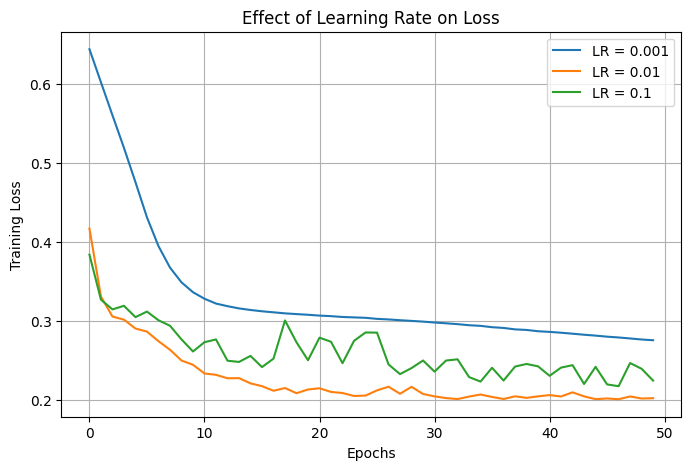

In [ ]:
plt.figure(figsize=(8, 5))

for lr, history in results_lr.items():

    plt.plot(
        history.history['loss'],
        label=f'LR = {lr}'
    )

plt.xlabel("Epochs")
plt.ylabel("Training Loss")
plt.title("Effect of Learning Rate on Loss")
plt.legend()
plt.grid()

plt.show()

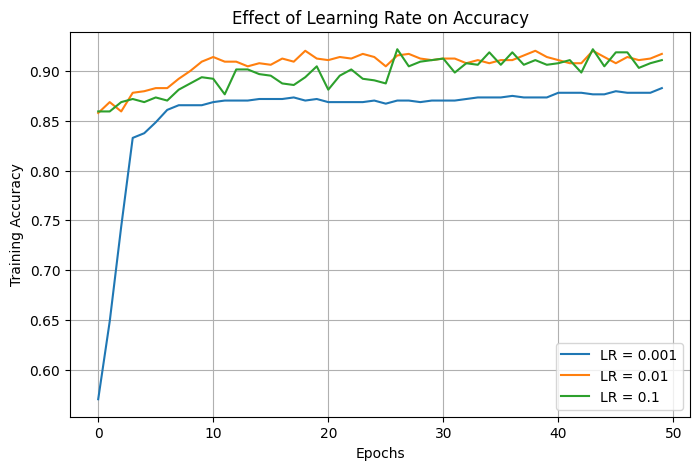

In [ ]:
plt.figure(figsize=(8, 5))

for lr, history in results_lr.items():

    plt.plot(
        history.history['accuracy'],
        label=f'LR = {lr}'
    )

plt.xlabel("Epochs")
plt.ylabel("Training Accuracy")
plt.title("Effect of Learning Rate on Accuracy")
plt.legend()
plt.grid()

plt.show()

In [ ]:
epoch_values = [10, 50, 100]

results_epochs = {}

for epochs in epoch_values:

    print("\nNumber of Epochs:", epochs)

    model = create_model(0.001)

    history = model.fit(
        X_train,
        y_train,
        epochs=epochs,
        batch_size=32,
        validation_split=0.2,
        verbose=0
    )

    test_loss, test_accuracy = model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    print("Test Loss:", test_loss)
    print("Test Accuracy:", test_accuracy)

    results_epochs[epochs] = history


Number of Epochs: 10
Test Loss: 0.3792667090892792
Test Accuracy: 0.875

Number of Epochs: 50
Test Loss: 0.2444048821926117
Test Accuracy: 0.8849999904632568

Number of Epochs: 100
Test Loss: 0.17943036556243896
Test Accuracy: 0.9200000166893005


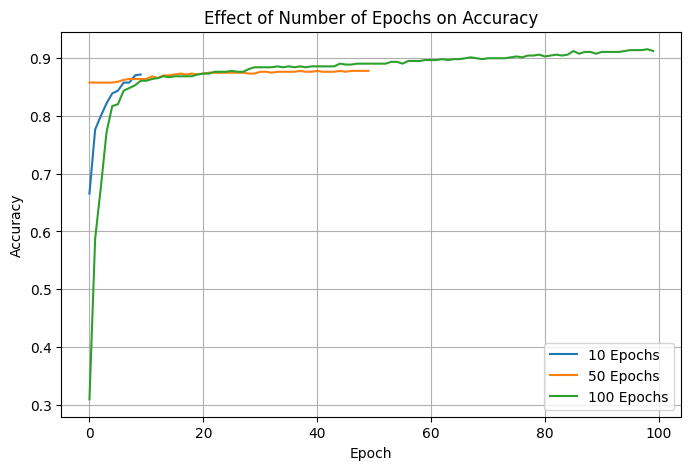

In [ ]:
plt.figure(figsize=(8, 5))

for epochs, history in results_epochs.items():

    plt.plot(
        history.history['accuracy'],
        label=f'{epochs} Epochs'
    )

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Effect of Number of Epochs on Accuracy")
plt.legend()
plt.grid()

plt.show()


In [ ]:
model = create_model(0.001)

history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)


Epoch 1/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.4000 - loss: 0.7168 - val_accuracy: 0.5250 - val_loss: 0.6857
Epoch 2/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5656 - loss: 0.6717 - val_accuracy: 0.7125 - val_loss: 0.6529
Epoch 3/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7984 - loss: 0.6319 - val_accuracy: 0.8313 - val_loss: 0.6201
Epoch 4/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8781 - loss: 0.5929 - val_accuracy: 0.8125 - val_loss: 0.5902
Epoch 5/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8719 - loss: 0.5564 - val_accuracy: 0.8125 - val_loss: 0.5615
Epoch 6/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8703 - loss: 0.5200 - val_accuracy: 0.8125 - val_loss: 0.5327
Epoch 7/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8687 - loss: 0.4858 - val_accuracy: 0.8062 - val_loss: 0.5044
Epoch 8/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8719 - loss: 0.4522 - val_accuracy: 0.8125 - val

In [ ]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("\nFinal Model Results")
print("-------------------")
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)


Final Model Results
-------------------
Test Loss: 0.2195458859205246
Test Accuracy: 0.8999999761581421


In [ ]:
predictions = model.predict(X_test)

predicted_classes = (predictions > 0.5).astype(int)

print("\nFirst 10 Predictions:")
print(predicted_classes[:10].flatten())

print("\nActual Values:")
print(y_test[:10])

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 

First 10 Predictions:
[0 1 1 0 0 0 1 1 0 1]

Actual Values:
[0 1 1 1 0 1 1 1 0 1]
